# Corrected VLM/GIA projections: two future-rate choices

Compare the corrected production package with `--vlm-rate-mode converge-to-gia` and `--vlm-rate-mode constant`. This notebook contains **only corrected results**, not the historical baseline.

The cities are **Venice, Skellefteå, London, Tokyo, Brisbane, and New York**. Each panel overlays the mean and mean ± one ensemble standard deviation for both modes.

These outputs are the VLM/GIA contribution to relative sea level (RSL), **not total climate-driven sea-level projections**. Representative city coordinates are listed below. See [README.md](README.md) for input data and execution instructions.

In [1]:
from pathlib import Path
import os
import sys

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "src/oelsmann24_verticallandmotion").is_dir()
)
sys.path.insert(0, str(ROOT))
from diagnostics import helpers as dh  # noqa: E402

# Change these paths or set the corresponding environment variables.
INPUT_DIR = Path(os.environ.get("VLM_INPUT_DIR", ROOT / "data/inputs/reference"))
OUTPUT_DIR = Path(
    os.environ.get("VLM_DIAGNOSTICS_DIR", ROOT / "data/diagnostics/shared_notebooks")
)
plt.rcParams.update(
    {
        "figure.dpi": 100,
        "font.size": 10,
        "axes.titlesize": 12,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

# These settings feed the actual production package.
config = dh.Config(
    input_dir=INPUT_DIR,
    output_dir=OUTPUT_DIR / "global_grid",
    baseyear=2000,
    start=2000,
    end=2300,
    step=10,
    nsamps=500,
    seed=1234,
)
MAP_YEAR = 2150
FORCE_RERUN = False
display(pd.DataFrame(dh.CITIES, columns=["city", "latitude", "longitude"]))

,city,latitude,longitude
0,Venice,45.4300,12.3300
1,Skellefteå,64.7500,21.0000
2,London,51.5074,-0.1278
3,Tokyo,35.6500,139.7700
4,Brisbane,-27.4700,153.0300
5,New York,40.7000,-74.0100


## Generate or load a verified cache

Both modes use the same inputs, locations, years, seed, and 500 samples. Source/input hashes, helper code, software versions and settings determine whether the cache can be reused. Mean and population standard deviation (`ddof=0`) are computed from the generated float32 samples using float64 reductions.

Large NetCDF outputs and standalone figures go to ignored `data/diagnostics/shared_notebooks/global_grid/`, separate from the earlier coastal-only run. No earlier local discovery workspace is needed to reproduce this notebook.

In [2]:
results, manifest = dh.ensure_projections(config, force=FORCE_RERUN)
assert set(results) == {"converge-to-gia", "constant"}
assert manifest["global_map_nodes"] == 180 * 360
for mode, dataset in results.items():
    assert dataset.vlm_rate_mode == mode
    assert dataset["mean"].dims == ("years", "locations")
    assert dh.global_map_field(dataset.isel(years=0), "mean").shape == (180, 360)
    assert not dataset["mean"].sel(years=config.baseyear).values.any()
display(
    pd.DataFrame(
        [
            {
                "samples": config.nsamps,
                "seed": config.seed,
                "base_year": config.baseyear,
                "start_year": config.start,
                "end_year": config.end,
                "step": config.step,
                "cities": len(dh.CITIES),
                "global_map_nodes": manifest["global_map_nodes"],
            }
        ]
    )
)
print("Run fingerprint:", manifest["fingerprint"])
print("Production source revision:", manifest["git_revision"])
print(manifest["git_note"])
display(
    pd.Series(manifest["provenance"]["input_sha256"], name="Input SHA256").to_frame()
)
display(pd.Series(manifest["provenance"]["versions"], name="Version").to_frame())

,samples,seed,base_year,start_year,end_year,step,cities,global_map_nodes
0,500,1234,2000,2000,2300,10,6,64800


Run fingerprint: 61e4cb680942578413832b2d38f0a59d3dc007de9978e4f20acc24633f1f8f9b
Production source revision: 1c4ab96fc29d9f1d174e99ed763a7eca02a72abc
Source hashes identify the actual code including uncommitted corrections.


,Input SHA256
VLM_reconstruction.nc,ba49439d6a3784f7e7bbaa35a1557c1f5fef4833ba99fd...
NGL14_CMR_corrected.nc,9dc9abec547c0b94169e09fe2766c041065afcb5bdd63d...
GIA_stats.nc,4f63bf2e0c367b92cd99c6c606f27f4a0f605a5d576044...
dist2coast_1deg_v2.grd,a9250561bce87c58afa1bad118715c6e27c10f48e3c0f0...
ssp585.2150.fair2.emuGLA.emulandice2.glaciers_quantiles.nc,f4c7b7e283f671b0f979a6dbd41f3fda2d46d17f01db3f...


,Version
numpy,2.2.3
scipy,1.17.0
xarray,2025.12.0
netCDF4,1.7.4
matplotlib,3.11.2
cartopy,0.26.0


## Cities: convergence versus constant secular rates

Blue: rates converge to GIA during 2050–2150 (shaded transition window), while retaining previously accumulated displacement. Orange: the selected secular rates continue unchanged.

The separate random-walk displacement-envelope treatment remains the same in both cases. This switch controls the mean secular rate and its trend uncertainty; it does not define new stochastic trajectories beyond the input GRW coverage. Mean ± standard deviation is an ensemble summary, not a guaranteed 68% credible interval.

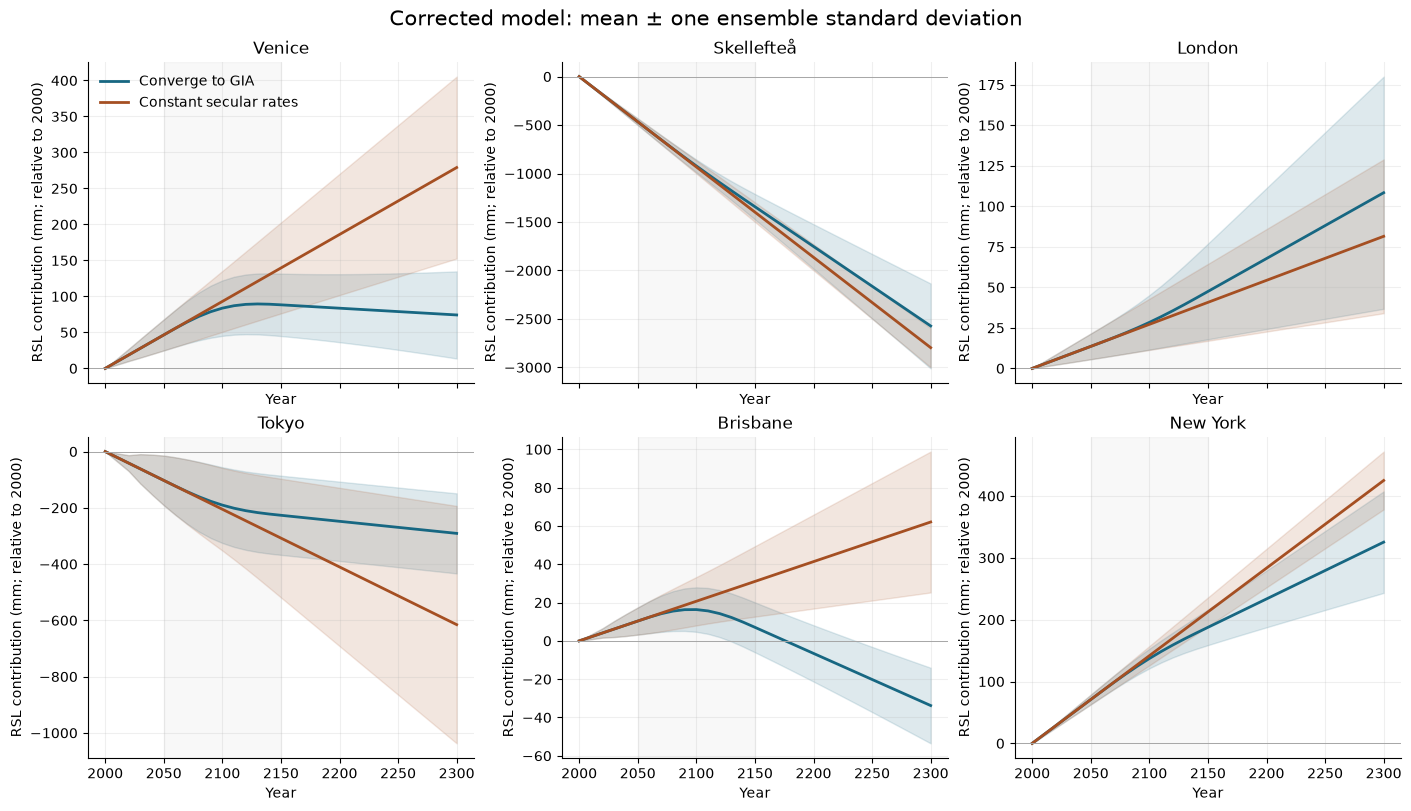

In [3]:
fig = dh.city_plot(results, config.baseyear)
dh.save_figure(fig, config, "projection_cities_both_modes.png")

## Maps: mean and standard deviation for both modes

Maps cover **every global 1° cell**, including the open ocean and land, with no coastal selection. Cell centers run from 89.5°S to 89.5°N and 179.5°W to 179.5°E; the displayed cells extend to the poles and the date line. Where observation weight is zero, the production model supplies GIA relative sea-level change and its uncertainty. White circles identify the six city locations. Both rows use the same color scale for the mean, and the same color scale for standard deviation.

The displayed color limits use the pooled 98th percentile for legibility; colorbar extensions flag clipping of colors only. Numeric data are unchanged. These locations are not an area-weighted global average. Change `MAP_YEAR` above to another saved decade to inspect it.

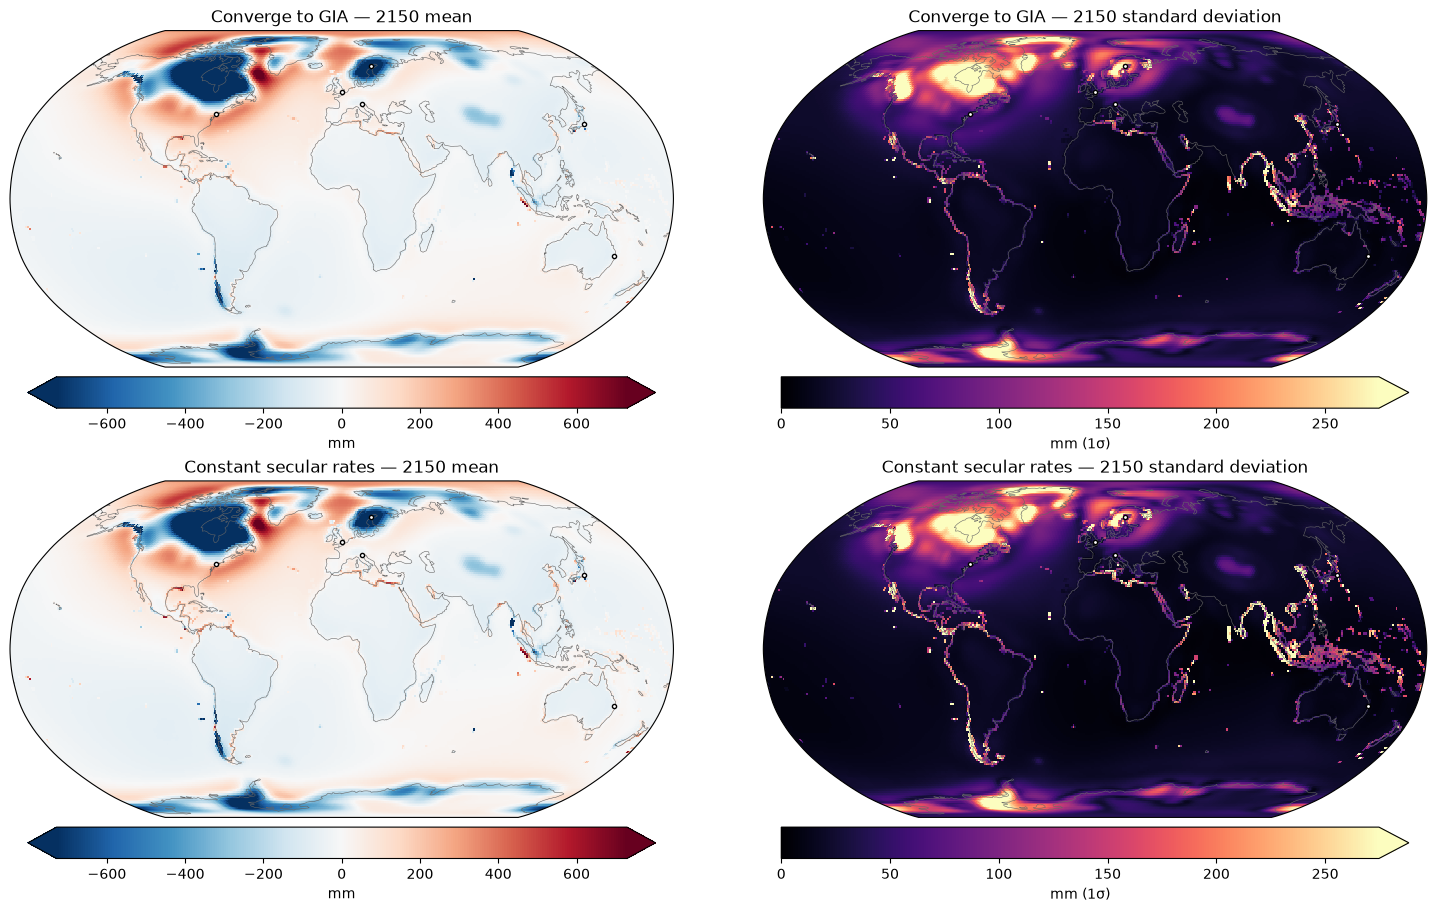

In [4]:
if MAP_YEAR not in results["constant"].years.values:
    raise ValueError("MAP_YEAR must be one of the saved projection years")
fig = dh.projection_maps(results, MAP_YEAR)
dh.save_figure(fig, config, f"projection_maps_{MAP_YEAR}_both_modes.png")

## Difference between future-rate choices

Constant minus convergence, for both the mean and the standard deviation. These differences isolate the future-rate choice: the corrected code, input datasets, site selection and random draws are otherwise identical. Open-ocean differences are zero because both modes use the same GIA contribution there, not because data are missing.

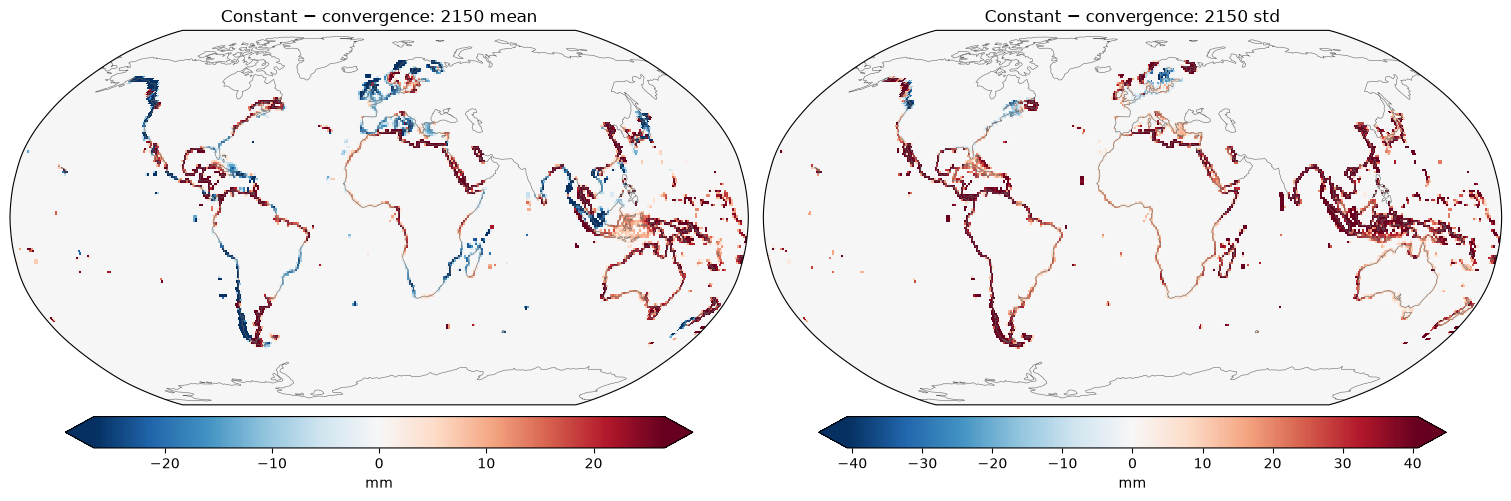

mean_mm  std_mm
city       mode                                   
Venice     Converge to GIA           88.33   43.37
           Constant secular rates   139.53   63.18
Skellefteå Converge to GIA        -1342.39  131.29
           Constant secular rates -1398.34  101.00
London     Converge to GIA           47.47   29.51
           Constant secular rates    40.74   23.72
Tokyo      Converge to GIA         -226.53  140.76
           Constant secular rates  -307.62  210.99
Brisbane   Converge to GIA            7.07   13.04
           Constant secular rates    31.03   18.39
New York   Converge to GIA          187.62   28.79
           Constant secular rates   212.55   23.39

In [5]:
fig = dh.difference_maps(results, MAP_YEAR)
dh.save_figure(fig, config, f"projection_difference_{MAP_YEAR}.png")

rows = []
for i, (name, _, _) in enumerate(dh.CITIES):
    for mode, dataset in results.items():
        rows.append(
            {
                "city": name,
                "mode": dh.MODES[mode],
                "mean_mm": float(dataset["mean"].isel(locations=i).sel(years=MAP_YEAR)),
                "std_mm": float(dataset["std"].isel(locations=i).sel(years=MAP_YEAR)),
            }
        )
summary = pd.DataFrame(rows).set_index(["city", "mode"])
display(summary.round(2))
summary.to_csv(config.output_dir / f"city_summary_{MAP_YEAR}.csv")

## Interpretation and reproducibility

- GIA-only locations have the same results in both cases; the spatial observation/GIA blend is preserved.
- Convergence retains accumulated non-GIA displacement. Constant secular rates and trend uncertainty continue accumulating over the requested projection period.
- The module already includes GIA. Adding a second complete GIA module output would double-count that contribution.
- Neither mode supplies a complete spatial covariance model or actual GRW sample paths. The GIA sea-surface correction remains a deterministic mean, and CMR treatment is unchanged.
- Finite-ensemble standard deviations include sampling variability. Actual generated samples are retained locally alongside the compact decadal mean/std products.
- Input SHA256 hashes, production/helper source hashes, dependency versions, run settings, output checksums and representative city coordinates are in the local `manifest.json`.
- Notebook source and embedded figures belong in Git. Raw inputs, generated NetCDF/PNG files and environment caches remain outside this folder, under ignored `data/`.